# Tutorial 2 — dataset1 (MERFISH) and the benchmark

**Part 1** runs CoSMIM on the five MERFISH sections of the mouse hypothalamic preoptic region (Moffitt *et al.*, *Science* 2018) used as dataset1. The sections and their domain labels (Li & Zhou, *Genome Biol.* 2022) are the version distributed with SDMBench.

**Part 2** compares sixteen methods on dataset1-6 with eight metrics and repeats the statistical tests.

**Part 3** follows gene-gene correlations through the domains of dataset1, on the fivesections and on section 0.19.

In [1]:
import sys
sys.path.insert(0, "../src")

import hashlib
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import cosmim
import os, urllib.request, warnings
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

## Part 1. CoSMIM on dataset1

### Download data

In [2]:
FILES = {"MERFISH_0.04": (40038526, "6911c3bb10945ae149f304bb8ce83a58"),
         "MERFISH_0.09": (40038529, "27ab06f65f492035f4ed0a897d6a0040"),
         "MERFISH_0.14": (40038532, "4317697dcc800d6c4deff09b3ce2ad80"),
         "MERFISH_0.19": (40038535, "c9d332611d149b31ae90f0a8b7c96621"),
         "MERFISH_0.24": (40038538, "3a1c86b3bd49b5cf3377f5207c4bf98c")}
# for name, (file_id, md5) in FILES.items():
#     path = f"../data/D1_merfish/{name}.h5ad"
#     urllib.request.urlretrieve(f"https://ndownloader.figshare.com/files/{file_id}", path)
# assert hashlib.md5(open(path, "rb").read()).hexdigest() == md5, name

### Run CoSMIM and clustering

In [3]:
table = pd.read_csv("../figures/fig2/benchmark_per_section.csv")
paper = table.query("dataset == 'dataset1' and method == 'CoSMIM'").set_index("section")["NMI"]

results, rows = {}, []
for name in FILES:
    adata = sc.read_h5ad(f"../data/D1_merfish/{name}.h5ad")
    r, adata_hvg = cosmim.spatial_preprocess_pipeline(adata, strategy="svg_hvg", n_top_hvg=64)
    adata_hvg.layers["log"] = np.log(adata_hvg.X + 1)
    features, weights = cosmim.compute_cosmim(adata_hvg)
    r.obs["cosmim"] = cosmim.run_leiden_partition(features, max_labels=cosmim.get_num_groups(r, "domain"), n_pcs=50, n_neighbors=300)
    r.obsm["cosmim"] = features
    r.uns["cosmim"] = {"genes": adata_hvg.var_names.tolist(), "weights": weights}
    results[name] = r
    rows.append({"section": name, "NMI": cosmim.calc_nmi(r, "domain", "cosmim"), "ARI": cosmim.calc_ari(r, "domain", "cosmim"), "NMI in the paper": paper[name]})
nmi = pd.DataFrame(rows).set_index("section")
print("median NMI:", round(nmi["NMI"].median(), 4), " paper:", round(paper.median(), 4))
nmi.round(4)

median NMI: 0.6796  paper: 0.6796


,NMI,ARI,NMI in the paper
section,,,
MERFISH_0.04,0.6776,0.5822,0.6544
MERFISH_0.09,0.6796,0.5967,0.6796
MERFISH_0.14,0.5751,0.5052,0.5751
MERFISH_0.19,0.6990,0.6137,0.6990
MERFISH_0.24,0.7040,0.6656,0.7040


## Part 2. Sixteen methods on dataset1-6

CoSMIM, the four methods run in this study (NichePCA, BANKSY, COVET, PCA+Leiden) and the eleven methods whose results SDMBench published. Each metric is first summarised by its median over the sections of a dataset.

In [4]:
METRICS = ["NMI", "HOM", "COM", "CHAOS", "PAS", "ASW", "MoranI", "GearyC"]
LOWER = {"CHAOS", "PAS", "GearyC"}
GROUPS = {"Accuracy": ["NMI", "HOM", "COM"], "Continuity": ["CHAOS", "PAS", "ASW"],
          "Marker": ["MoranI", "GearyC"]}
ORDER = ["CoSMIM", "NichePCA", "SCAN-IT", "BASS", "BANKSY", "COVET", "SpaceFlow", "DeepST",
         "CCST", "STAGATE", "SpaGCN", "PCA+Leiden", "SEDR", "Leiden", "Louvain", "conST"]
DATASETS = ["dataset1", "dataset2", "dataset3", "dataset4", "dataset5", "dataset6"]

per = table[table["dataset"].isin(DATASETS)].groupby(["dataset", "method"])[METRICS].median()


def rank_methods(values):
    """Rank the methods within each metric: 16 = best, ties share the lower rank."""
    return pd.DataFrame({m: values[m].rank(ascending=m not in LOWER, method="min")
                         for m in METRICS})

### Eight metrics

One box per method over its six per-dataset medians; points beyond the whiskers (1.5 × IQR) are not drawn. Metrics marked ↓ are better when lower and have reversed axes, so the better end is on the right in every panel.

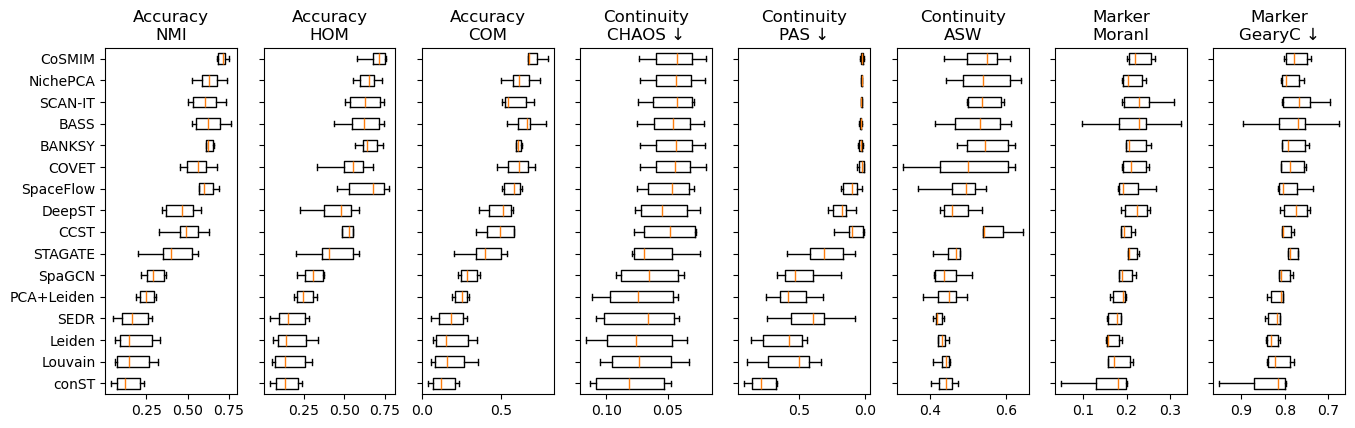

In [5]:
methods = ORDER[::-1]
fig, axes = plt.subplots(1, 8, figsize=(16, 4.5), sharey=True)
for ax, (group, m) in zip(axes, [(g, m) for g, cols in GROUPS.items() for m in cols]):
    ax.boxplot([per.xs(method, level="method")[m].dropna() for method in methods],
               orientation="horizontal", showfliers=False)
    ax.set_title(f"{group}\n{m} ↓" if m in LOWER else f"{group}\n{m}")
    if m in LOWER:
        ax.invert_xaxis()
axes[0].set_yticks(range(1, len(methods) + 1), methods)
plt.show()

### Summed ranks

For each metric the methods are ranked on their median over the datasets (16 = best), and the eight ranks are summed (maximum 128).

In [6]:
ranks = rank_methods(per.groupby("method").median())
for group, cols in GROUPS.items():
    ranks[group] = ranks[cols].sum(axis=1)
ranks["Total"] = ranks[METRICS].sum(axis=1)
ranks = ranks.sort_values(["Total", "Accuracy"], ascending=False)
ranks[["Accuracy", "Continuity", "Marker", "Total"]].astype(int)

,Accuracy,Continuity,Marker,Total
method,,,,
CoSMIM,48,47,26,121
SCAN-IT,34,41,31,106
BASS,39,33,31,103
NichePCA,42,40,18,100
BANKSY,39,41,20,100
COVET,34,37,23,94
SpaceFlow,37,29,15,81
DeepST,25,23,28,76
CCST,26,32,15,73


### Ranks within each dataset

Within each dataset the eight metric ranks are averaged and the methods are ranked on that mean (16 = best).

In [7]:
dataset_ranks = pd.DataFrame({
    ds: rank_methods(block.droplevel("dataset")).mean(axis=1).rank(method="min")
    for ds, block in per.groupby(level="dataset")})[DATASETS]
dataset_ranks.loc[ORDER].astype("Int64")

,dataset1,dataset2,dataset3,dataset4,dataset5,dataset6
method,,,,,,
CoSMIM,16,16,12,16,16,14
NichePCA,10,14,14,15,12,9
SCAN-IT,13,13,15,14,10,8
BASS,15,10,16,11,13,5
BANKSY,11,15,11,12,15,13
COVET,8,9,10,13,14,7
SpaceFlow,14,12,9,8,9,1
DeepST,9,8,8,10,8,12
CCST,11,6,12,9,7,<NA>


### Median NMI and statistical tests

The five methods run in this study are compared on all 25 sections of the seven datasets: the median NMI of each dataset, a two-sided paired Wilcoxon signed-rank test of CoSMIM against each competitor, and the Friedman test followed by the Nemenyi post-hoc test.

In [8]:
five = ["CoSMIM", "NichePCA", "BANKSY", "COVET", "PCA+Leiden"]
table[table.method.isin(five)].groupby(["dataset", "method"])["NMI"].median().unstack()[five].round(3)

method,CoSMIM,NichePCA,BANKSY,COVET,PCA+Leiden
dataset,,,,,
dataset1,0.680,0.575,0.611,0.522,0.250
dataset2,0.709,0.618,0.614,0.456,0.197
dataset3,0.749,0.739,0.739,0.681,0.191
dataset4,0.731,0.689,0.637,0.617,0.252
dataset5,0.715,0.644,0.661,0.602,0.312
dataset6,0.556,0.526,0.541,0.487,0.471
dataset7,0.659,0.637,0.614,0.641,0.455


In [9]:
nmi_all = table[table.method.isin(five)].pivot(index="section", columns="method", values="NMI")[five]
competitors = five[1:]
tests = pd.DataFrame(
    [{"competitor": c, "sections": len(nmi_all),
      "CoSMIM higher": int((nmi_all["CoSMIM"] > nmi_all[c]).sum()),
      "Wilcoxon P": stats.wilcoxon(nmi_all["CoSMIM"], nmi_all[c], alternative="two-sided",
                                   zero_method="wilcox").pvalue}
     for c in competitors]).set_index("competitor")

chi2, p = stats.friedmanchisquare(*[nmi_all[m] for m in five])
print(f"Friedman chi2 = {chi2:.2f}, P = {p:.2e}")
print("mean rank (1 = highest NMI):", nmi_all.rank(axis=1, ascending=False).mean().round(2).to_dict())

k, n = len(five), len(nmi_all)
mean_ranks = nmi_all.rank(axis=1).mean()
tests["Nemenyi P"] = [stats.studentized_range.sf(
    abs(mean_ranks["CoSMIM"] - mean_ranks[c]) / np.sqrt(k * (k + 1) / (6 * n)) * np.sqrt(2),
    k, np.inf) for c in competitors]
tests

Friedman chi2 = 65.82, P = 1.73e-13
mean rank (1 = highest NMI): {'CoSMIM': 1.32, 'NichePCA': 2.6, 'BANKSY': 2.56, 'COVET': 3.92, 'PCA+Leiden': 4.6}


,sections,CoSMIM higher,Wilcoxon P,Nemenyi P
competitor,,,,
NichePCA,25,22,1.398921e-04,3.419861e-02
BANKSY,25,22,9.118915e-04,4.413999e-02
COVET,25,24,8.344650e-07,6.097273e-08
PCA+Leiden,25,24,1.192093e-07,2.228662e-12


## Part 3. Gene-gene correlations on dataset1

The niche covariance of a cell is Σ = S·S, where S is its CoSMIM feature unpacked into the symmetric square root. The correlation matrix of a domain comes from the mean Σ of its cells. Each section selects its own 64 genes, so matrices of different sections are compared by gene name.

In [10]:
def niche_sigma(features):
    """Niche covariance of each cell, S @ S."""
    g = int((np.sqrt(8 * features.shape[1] + 1) - 1) / 2)
    S = cosmim.from_tril(np.asarray(features, dtype=np.float64), g)
    return np.einsum("nij,njk->nik", S, S)


def to_corr(cov):
    """Covariance -> correlation."""
    sd = np.sqrt(np.clip(np.diag(cov), 1e-12, None))
    return cov / np.outer(sd, sd)


def hungarian_map(gt, pred):
    """Cluster -> annotated domain, one to one (Hungarian); the rest by largest overlap."""
    gts, prs = sorted(set(gt)), sorted(set(pred))
    M = np.array([[np.sum((pred == p) & (gt == q)) for q in gts] for p in prs], dtype=float)
    rows, cols = linear_sum_assignment(-M)
    mapping = {prs[i]: gts[j] for i, j in zip(rows, cols)}
    for i, p in enumerate(prs):
        mapping.setdefault(p, gts[int(M[i].argmax())])
    return mapping


sections = sorted(results)
corr_by_section, genes_by_section = {}, {}
for s in sections:
    r = results[s]
    sigma = niche_sigma(r.obsm["cosmim"]).astype(np.float32)
    domain = r.obs["domain"].astype(str).values
    corr_by_section[s] = {d: to_corr(sigma[domain == d].mean(0).astype(np.float64)).astype(np.float32)
                          for d in sorted(set(domain)) if d.lower() != "nan"}
    genes_by_section[s] = list(r.uns["cosmim"]["genes"])

union = list(dict.fromkeys(g for s in sections for g in genes_by_section[s]))
iu = np.triu_indices(len(union), k=1)
pair_names = np.array([f"{union[i]}-{union[j]}" for i, j in zip(*iu)])


def on_union(mat, genes):
    idx = np.array([genes.index(g) if g in genes else -1 for g in union])
    ok = idx >= 0
    safe = np.where(ok, idx, 0)
    out = np.asarray(mat, dtype=np.float64)[np.ix_(safe, safe)]
    out[~ok, :] = np.nan
    out[:, ~ok] = np.nan
    return out[iu]


V = {(s, d): on_union(m, genes_by_section[s]) for s in sections for d, m in corr_by_section[s].items()}
domains_all = sorted({d for _, d in V})
print(len(union), "genes in the union,", len(pair_names), "gene pairs")

96 genes in the union, 4560 gene pairs


In [11]:
DOMAIN_ORDER = ["V3", "fx", "PVT", "PV", "MPA", "PVH", "BST", "MPN"]
DOMAIN_COLOURS = dict(zip(DOMAIN_ORDER, ["#bcbd22", "#17becf", "#7f7f7f", "#9467bd",
                                         "#ff7f0e", "#8c564b", "#1f77b4", "#2ca02c"]))

### One gene pair across domains

The correlation of gene pair in each annotated domain: bars are the mean over the five sections, points the single sections.

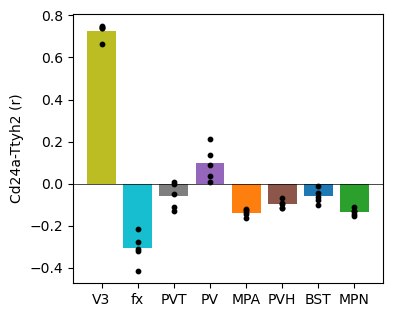

In [12]:
pair = pair_names.tolist().index("Cd24a-Ttyh2")
flip = pd.DataFrame([{"domain": d, "section": s, "r": V[(s, d)][pair]}
                     for (s, d) in V if np.isfinite(V[(s, d)][pair])])
means = flip.groupby("domain")["r"].mean()
order = [d for d in DOMAIN_ORDER if d in means.index]

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(order, means[order], color=[DOMAIN_COLOURS[d] for d in order])
for d in order:
    values = flip.loc[flip.domain == d, "r"]
    ax.scatter([d] * len(values), values, color="black", s=10)
ax.axhline(0, color="black", lw=0.5)
ax.set_ylabel("Cd24a-Ttyh2 (r)")
plt.show()

### Gene pairs specific to V3

For each gene pair and section, the V3 contrast is the pair's correlation in V3 minus its median over the other domains of the same section. The contrast is tested across sections with a two-sided one-sample *t* test (on the sections that selected both genes, at least three), and the *P* values are corrected with Benjamini–Hochberg. Among the significant pairs tested on all five sections, the twelve with the largest mean contrast are shown.

946 pairs at q < 0.05, 402 of them tested on all five sections


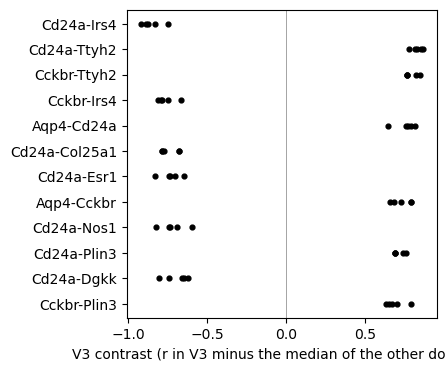

,pair,column,mean_contrast,q,n_sections,all_sections
0,Cd24a-Irs4,749,-0.8524,0.0008,5,True
2,Cd24a-Ttyh2,772,0.8269,0.0005,5,True
3,Cckbr-Ttyh2,597,0.7908,0.0005,5,True
4,Cckbr-Irs4,574,-0.7606,0.0008,5,True
5,Aqp4-Cd24a,101,0.7523,0.0008,5,True
6,Cd24a-Col25a1,733,-0.7414,0.0008,5,True
8,Cd24a-Esr1,742,-0.7308,0.0008,5,True
9,Aqp4-Cckbr,99,0.7274,0.0008,5,True
11,Cd24a-Nos1,754,-0.7176,0.0009,5,True
12,Cd24a-Plin3,761,0.7117,0.0005,5,True


In [13]:
contrast = []
for s in sections:
    dd = {d: V[(s, d)] for d in domains_all if (s, d) in V}
    if "V3" in dd and len(dd) >= 3:
        other = np.stack([v for d, v in dd.items() if d != "V3"])
        contrast.append(dd["V3"] - np.median(other, axis=0))
contrast = np.vstack(contrast)

with np.errstate(invalid="ignore", divide="ignore"), warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    n_sec = np.isfinite(contrast).sum(0)
    mean_c = np.nanmean(contrast, axis=0)
    t = mean_c / (np.nanstd(contrast, axis=0, ddof=1) / np.sqrt(n_sec))
    p = 2 * stats.t.sf(np.abs(t), np.maximum(n_sec - 1, 1))
p[n_sec < 3] = np.nan


def benjamini_hochberg(p):
    q = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    order = np.argsort(p[ok])
    m = ok.sum()
    adjusted = np.minimum.accumulate((p[ok][order] * m / np.arange(1, m + 1))[::-1])[::-1]
    q_ok = np.empty(m)
    q_ok[order] = np.clip(adjusted, 0, 1)
    q[ok] = q_ok
    return q


v3 = pd.DataFrame({"pair": pair_names, "column": np.arange(len(pair_names)),
                   "mean_contrast": np.round(mean_c, 4), "q": np.round(benjamini_hochberg(p), 4),
                   "n_sections": n_sec, "all_sections": n_sec == len(contrast)})
significant = v3[v3.q < 0.05]
significant = significant.reindex(significant.mean_contrast.abs().sort_values(ascending=False).index)
significant = significant.reset_index(drop=True)
print(len(significant), "pairs at q < 0.05,", int(significant.all_sections.sum()), "of them tested on all five sections")
shown = significant[significant.all_sections]
shown = shown.reindex(shown.mean_contrast.abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(figsize=(4, 4))
for k, column in enumerate(shown.column):
    ax.scatter(contrast[:, column], [k] * len(contrast), color="black", s=12)
ax.set_yticks(range(len(shown)), shown.pair)
ax.invert_yaxis()
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("V3 contrast (r in V3 minus the median of the other domains)")
plt.show()
shown

### The competitors on section 0.19

The panels below compare CoSMIM with NichePCA, BANKSY, COVET and PCA+Leiden.

In [14]:
#   pip install nichepca==0.1.0 pybanksy==1.3.4 scenvi==0.4.6 jax==0.4.29
#
# import anndata as ad
# import banksy.run_banksy as banksy_run
# import nichepca as npc
# from banksy.initialize_banksy import initialize_banksy
# from scenvi.utils import compute_covet
#
# def leiden_to(adata, n, seed=1234):
#     """Leiden with n clusters on the existing graph."""
#     res = cosmim.find_resolution(adata, n, random_state=seed)
#     sc.tl.leiden(adata, resolution=res, random_state=seed, flavor="igraph", n_iterations=2)
#     return adata.obs["leiden"].values
#
# def run_competitors(adata, annotation_key, n_hvg=64, seed=1234):
#     """Clusters of NichePCA (k=15), BANKSY (k=20), COVET (k=8) and PCA+Leiden (30 PCs)."""
#     raw, hvg = cosmim.spatial_preprocess_pipeline(adata, strategy="svg_hvg", n_top_hvg=n_hvg)
#     n = cosmim.get_num_groups(raw, annotation_key)
#     out = pd.DataFrame(index=raw.obs_names)
#
#     a = raw.copy()                                        # NichePCA
#     npc.wf.nichepca(a, knn=15, n_comps=8)
#     sc.pp.neighbors(a, use_rep="X_npca", n_neighbors=15, random_state=seed)
#     out["NichePCA"] = leiden_to(a, n)
#
#     a = raw.copy()                                        # BANKSY
#     a.obs["x"], a.obs["y"] = a.obsm["spatial"][:, 0], a.obsm["spatial"][:, 1]
#     params = initialize_banksy(a, coord_keys=("x", "y", "spatial"), num_neighbours=20,
#                                nbr_weight_decay="scaled_gaussian", max_m=1,
#                                plt_edge_hist=False, plt_nbr_weights=False)
#     banksy_run.subplot_sc = lambda *args, **kwargs: None
#     result = banksy_run.run_banksy_multiparam(
#         a, params, lambda_list=[0.8], resolutions=[], max_m=1, pca_dims=[15],
#         color_list=list(plt.cm.tab20.colors) * 10, filepath="banksy_tmp",
#         key=("scaled_gaussian",), savefig=False, add_nonspatial=False, annotation_key=None,
#         max_labels=n, cluster_algorithm="leiden", partition_seed=seed)
#     out["BANKSY"] = result.iloc[-1]["labels"].dense
#
#     h = hvg.copy()                                        # COVET, on the same genes
#     h.X = h.X.toarray() if hasattr(h.X, "toarray") else h.X
#     _, covet_sqrt, _ = compute_covet(h, k=8, g=h.n_vars)
#     f = ad.AnnData(X=covet_sqrt.reshape(len(h), -1).astype(np.float32))
#     sc.pp.pca(f, n_comps=30, random_state=seed)
#     sc.pp.neighbors(f, n_neighbors=50, n_pcs=30, random_state=seed)
#     out["COVET"] = leiden_to(f, n)
#
#     x = hvg.X.toarray() if hasattr(hvg.X, "toarray") else hvg.X   # PCA + Leiden
#     f = ad.AnnData(X=np.asarray(x, dtype=np.float32))
#     sc.pp.pca(f, n_comps=30, random_state=seed)
#     sc.pp.neighbors(f, n_neighbors=50, n_pcs=30, use_rep="X_pca", random_state=seed)
#     out["PCA+Leiden"] = leiden_to(f, n)
#     return out
#
# competitors = run_competitors(sc.read_h5ad("../data/D1_merfish/MERFISH_0.19.h5ad"), "domain")
#
# raw, hvg = cosmim.spatial_preprocess_pipeline(sc.read_h5ad("../data/D1_merfish/MERFISH_0.19.h5ad"),
#                                               strategy="svg_hvg", n_top_hvg=64)
# h = hvg.copy()
# covet, covet_sqrt, covet_genes = compute_covet(h, k=8, g=h.n_vars)
# f = ad.AnnData(X=covet_sqrt.reshape(len(h), -1).astype(np.float32))
# sc.pp.pca(f, n_comps=30, random_state=1234)
# sc.pp.neighbors(f, n_neighbors=50, n_pcs=30, random_state=1234)
# cluster = leiden_to(f, cosmim.get_num_groups(raw, "domain")).astype(str)
# sc.tl.umap(f, random_state=1234)
# gt = raw.obs["domain"].astype(str).values
# mapping = hungarian_map(gt, cluster)
# covet_clusters = pd.DataFrame({"umap_x": f.obsm["X_umap"][:, 0], "umap_y": f.obsm["X_umap"][:, 1],
#                                "cluster": cluster}, index=raw.obs_names)
# pred = np.array([mapping[c] for c in cluster])
# rows = []
# for partition, labels in (("annotated", gt), ("predicted", pred)):
#     for d in sorted(set(labels)):
#         m = to_corr(covet[labels == d].mean(0))
#         rows.append(pd.Series(m[np.triu_indices(len(m), 1)], name=(partition, d)))
# covet_corr = pd.concat(rows, axis=1)
# covet_corr.index = [f"{a}-{b}" for a, b in zip(*[np.asarray(covet_genes)[i] for i in np.triu_indices(len(covet_genes), 1)])]

In [15]:
competitors = pd.read_csv("../figures/fig3/competitors_MERFISH_0.19.csv", index_col=0).astype(str)
covet_corr = pd.read_csv("../figures/fig3/covet_correlations_MERFISH_0.19.csv", index_col=0, header=[0, 1])

r19 = results["MERFISH_0.19"]
covet_clusters = pd.read_csv("../figures/fig3/covet_MERFISH_0.19.csv", index_col=0).loc[r19.obs_names]
gt = r19.obs["domain"].astype(str).values
labels = pd.DataFrame({"CoSMIM": r19.obs["cosmim"].astype(str).values}, index=r19.obs_names)
labels = labels.join(competitors.loc[r19.obs_names])

### Domains found by each method

The annotation of section 0.19 and the clusters of the five methods.

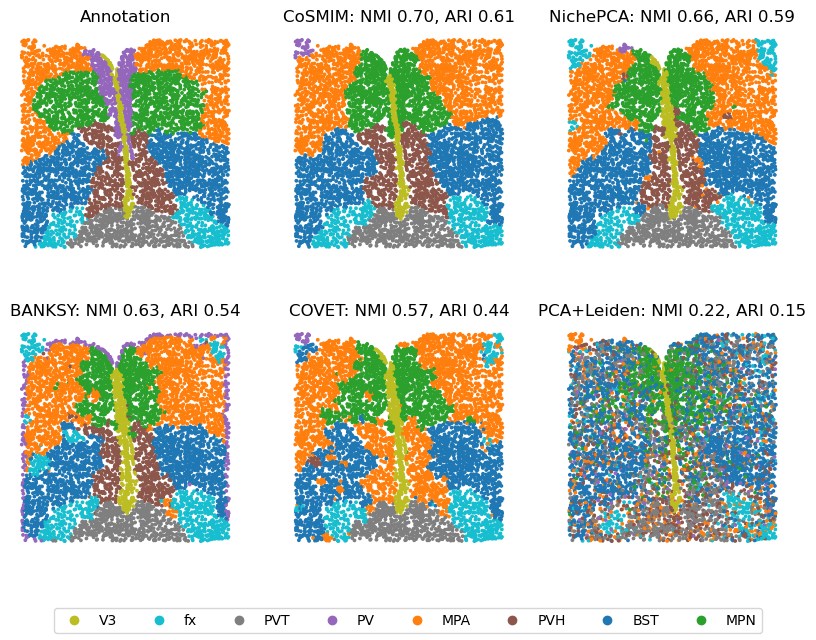

In [16]:
xy = r19.obsm["spatial"]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
axes = axes.ravel()
axes[0].scatter(xy[:, 0], xy[:, 1], c=[DOMAIN_COLOURS[d] for d in gt], s=3)
axes[0].set_title("Annotation")
scores_3a = {}
for ax, method in zip(axes[1:], labels.columns):
    pred = labels[method].values
    mapping = hungarian_map(gt, pred)
    scores_3a[method] = (normalized_mutual_info_score(gt, pred), adjusted_rand_score(gt, pred))
    ax.scatter(xy[:, 0], xy[:, 1], c=[DOMAIN_COLOURS[mapping[c]] for c in pred], s=3)
    ax.set_title(f"{method}: NMI {scores_3a[method][0]:.2f}, ARI {scores_3a[method][1]:.2f}")
for ax in axes:
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
fig.legend([plt.Line2D([], [], marker="o", ls="", color=DOMAIN_COLOURS[d]) for d in DOMAIN_ORDER],
           DOMAIN_ORDER, loc="lower center", ncol=8)
plt.show()

### UMAP of the features

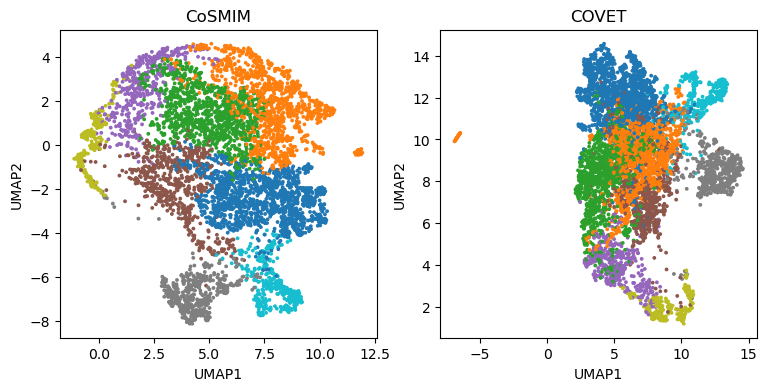

In [17]:
f = sc.AnnData(r19.obsm["cosmim"])
sc.pp.pca(f, n_comps=50, random_state=1234)
sc.pp.neighbors(f, n_neighbors=300, n_pcs=50, use_rep="X_pca", random_state=1234)
sc.tl.umap(f, random_state=1234)
cosmim_map = hungarian_map(gt, labels["CoSMIM"].values)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (method, u) in zip(axes, [("CoSMIM", f.obsm["X_umap"]),
                                  ("COVET", covet_clusters[["umap_x", "umap_y"]].values)]):
    ax.scatter(u[:, 0], u[:, 1], c=[DOMAIN_COLOURS[d] for d in gt], s=3)
    ax.set_title(method)
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
plt.show()

### Predicted against annotated domains

The correlation of every gene pair in each predicted domain against the same pair in the matched annotated domain.

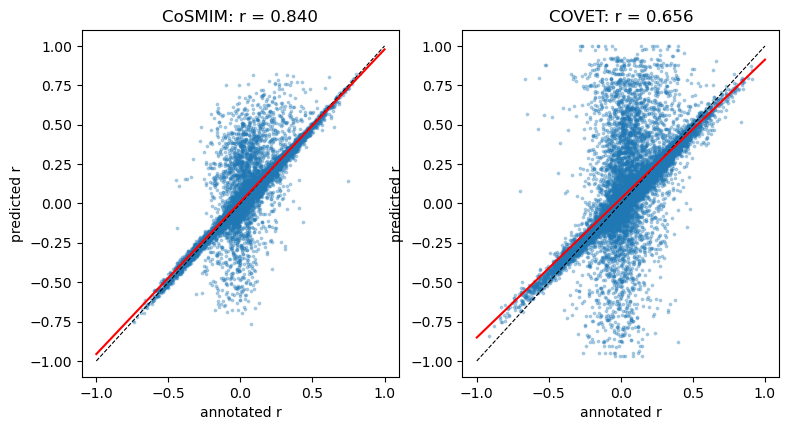

In [18]:
sigma = niche_sigma(r19.obsm["cosmim"])
genes19 = genes_by_section["MERFISH_0.19"]
pred_gt = np.array([cosmim_map[c] for c in labels["CoSMIM"]])
domains = list(covet_corr["annotated"].columns)
iu19 = np.triu_indices(len(genes19), k=1)


def pair_table(labels_):
    return pd.DataFrame({d: to_corr(sigma[labels_ == d].mean(0))[iu19] for d in domains},
                        index=[f"{genes19[i]}-{genes19[j]}" for i, j in zip(*iu19)])


cosmim_corr = {"annotated": pair_table(gt), "predicted": pair_table(pred_gt)}
covet_tables = {part: covet_corr[part].loc[cosmim_corr["annotated"].index, domains] for part in ("annotated", "predicted")}

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
concordance = {}
for ax, (method, tables) in zip(axes, [("CoSMIM", cosmim_corr), ("COVET", covet_tables)]):
    a, b = tables["annotated"].values.ravel(), tables["predicted"].values.ravel()
    concordance[method] = np.corrcoef(b, a)[0, 1]
    ax.scatter(a, b, s=3, alpha=0.3)
    ax.plot([-1, 1], [-1, 1], "k--", lw=0.8)
    ax.plot([-1, 1], np.polyval(np.polyfit(a, b, 1), [-1, 1]), color="red")
    ax.set_title(f"{method}: r = {concordance[method]:.3f}")
    ax.set_xlabel("annotated r")
    ax.set_ylabel("predicted r")
plt.show()

### Gene pairs that differ most between domains

The twelve pairs with the largest range across domains in CoSMIM's annotated matrices (no gene used twice), in the annotated and in the predicted domains of CoSMIM and COVET. The table gives, for V3 and PVH, the IoU of the cluster that overlaps the domain most and the mean absolute difference between its correlations and the domain's over all 2,016 pairs.

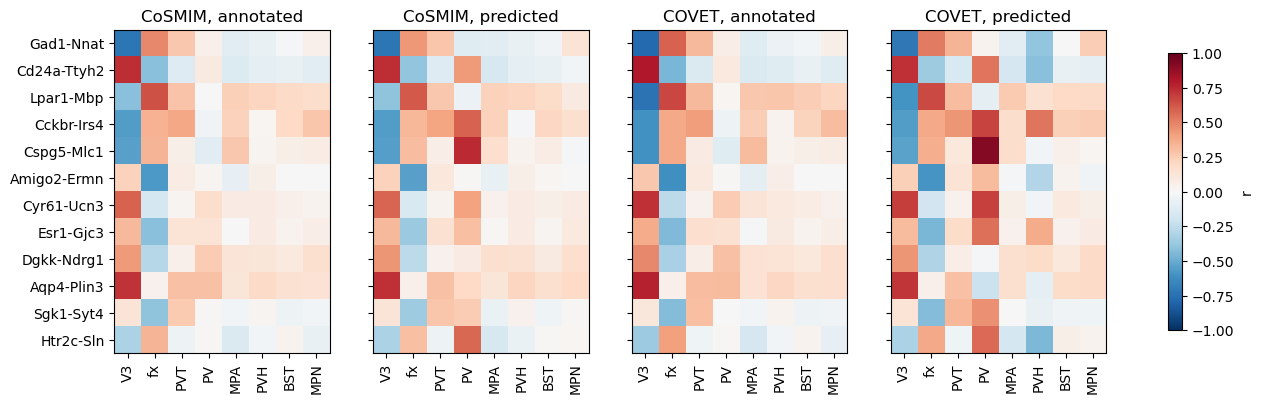

,domain,method,cluster,IoU,error
0,V3,CoSMIM,V3,0.796,0.011
1,V3,COVET,V3,0.672,0.047
2,PVH,CoSMIM,PVH,0.758,0.012
3,PVH,COVET,MPA,0.225,0.045


In [19]:
block = cosmim_corr["annotated"].values
spread = block.max(axis=1) - block.min(axis=1)
used, top = set(), []
for position in np.argsort(spread)[::-1]:
    name = cosmim_corr["annotated"].index[position]
    a, b = name.split("-")
    if a in used or b in used:
        continue
    used.update((a, b))
    top.append(name)
    if len(top) == 12:
        break

covet_assign = hungarian_map(gt, labels["COVET"].values)
assigned = {"CoSMIM": pred_gt, "COVET": np.array([covet_assign[c] for c in labels["COVET"]])}
marks = []
for d in ["V3", "PVH"]:
    truth = gt == d
    for method, tables in [("CoSMIM", cosmim_corr), ("COVET", covet_tables)]:
        iou = {c: (truth & (assigned[method] == c)).sum() / (truth | (assigned[method] == c)).sum()
               for c in pd.unique(assigned[method]) if c in tables["predicted"].columns}
        best = max(iou, key=iou.get)
        error = (tables["predicted"][best] - tables["annotated"][d]).abs().mean()
        marks.append({"domain": d, "method": method, "cluster": best, "IoU": iou[best], "error": error})

cols = [d for d in DOMAIN_ORDER if d in domains]
panels = [("CoSMIM", "annotated", cosmim_corr), ("CoSMIM", "predicted", cosmim_corr),
          ("COVET", "annotated", covet_tables), ("COVET", "predicted", covet_tables)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharey=True)
for ax, (method, part, tables) in zip(axes, panels):
    im = ax.imshow(tables[part].loc[top, cols].values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=90)
    ax.set_title(f"{method}, {part}")
axes[0].set_yticks(range(len(top)), top)
fig.colorbar(im, ax=axes, shrink=0.8, label="r")
plt.show()
pd.DataFrame(marks).round(3)